# 08 — ML Prediction (Section 19)

Trains models to predict `energy_consumption`, `completion_time`, and
`task_risk` from `data/dataset/ml/prediction_dataset.csv` (12,000 rows),
using the feature set the spec specifies. Three models are compared per
target — Linear Regression (baseline), Random Forest, and Gradient
Boosting (used in place of XGBoost, which is not installed in this
environment — documented, not silently substituted) — and the best model
per target (by held-out R²) is saved and wired into the auction as an
**optional** prediction component (Section 19: "feed the auction", not
replace it).

In [1]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))
import pandas as pd
import matplotlib.pyplot as plt

from ml_prediction import train_all, Predictor, FEATURES_ALL, TARGETS

DATASET_ROOT = "../data/dataset"
MODELS_DIR = "../models"

df = pd.read_csv(os.path.join(DATASET_ROOT, "ml", "prediction_dataset.csv"))
print(f"{len(df)} rows, {df.isnull().sum().sum()} nulls")
df.head()


12000 rows, 0 nulls


,robot_type,soc,dod,soh,distance,path_length,speed,task_workload,task_priority,zone_type,zone_risk,robot_load,temperature_or_environment_factor,energy_consumption,completion_time,task_risk
0,USV,73.71,27.13,0.843,22.76,30.86,4.25,16.36,2,AIR,1.18,0.187,19.39,117.332,32.751,2.735
1,UGV,52.47,48.16,0.926,49.84,53.69,1.55,29.43,1,RESTRICTED,4.66,0.578,18.87,191.557,86.940,6.860
2,USV,62.55,36.37,0.797,84.85,106.57,2.93,26.52,2,LAND,2.25,0.525,30.78,307.569,102.957,3.998
3,USV,72.25,27.07,0.776,75.32,83.35,4.38,32.91,5,AIR,0.50,0.811,28.50,254.464,112.739,3.114
4,USV,12.36,87.26,0.882,22.64,27.54,4.34,19.38,2,WATER,2.71,0.927,32.43,119.304,78.123,6.072


### Feature correlation heatmap (EDA)

Before trusting model feature-importance rankings, it helps to see which
input features are already correlated with each other and with the three
prediction targets.

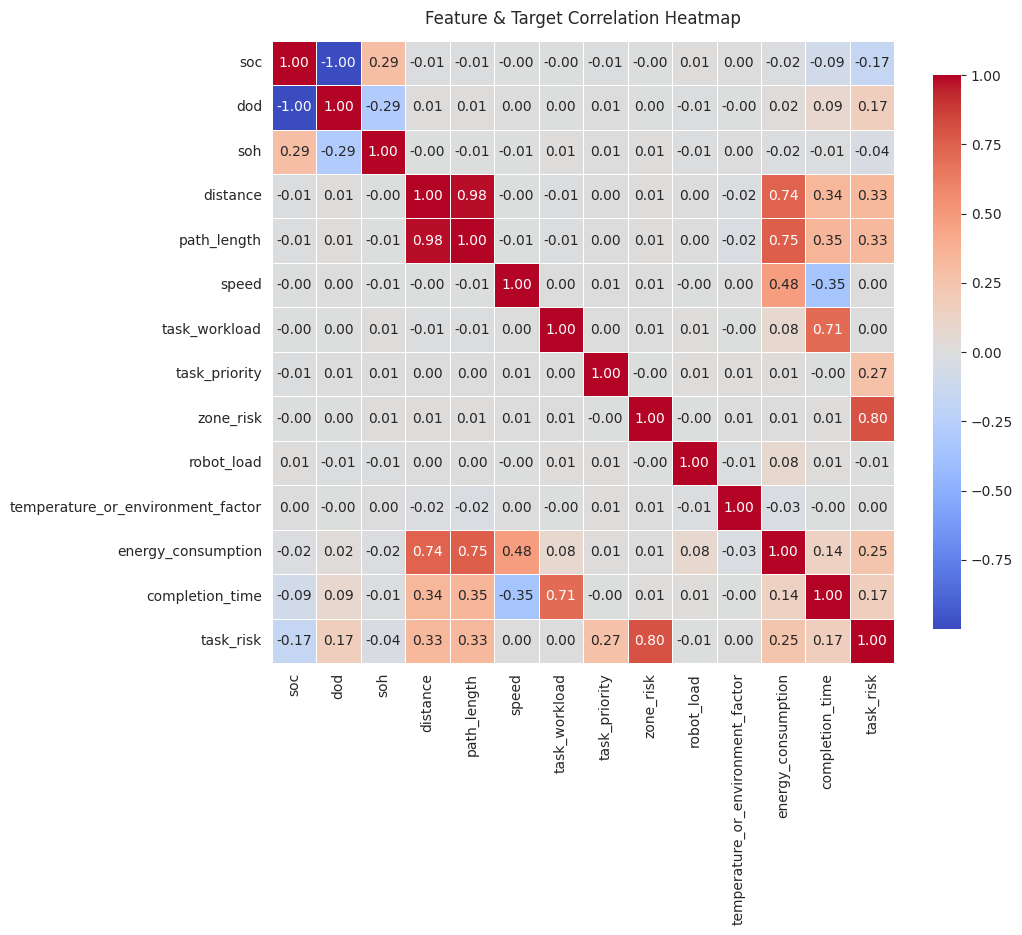

In [2]:
from visualization import plot_correlation_heatmap
from ml_prediction import FEATURES_NUMERIC

corr_cols = FEATURES_NUMERIC + TARGETS
plot_correlation_heatmap(df, corr_cols, title="Feature & Target Correlation Heatmap")
plt.savefig("../results/day4_ml_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## Train Linear / Random Forest / Gradient Boosting for each target

In [3]:
results = train_all(dataset_root=DATASET_ROOT, models_dir=MODELS_DIR)
results_df = pd.DataFrame([{"target": r.target, "model": r.model_name, "R2": r.r2, "MAE": r.mae} for r in results])
results_df.sort_values(["target", "R2"], ascending=[True, False])


,target,model,R2,MAE
5,completion_time,gradient_boosting,0.873646,8.800037
4,completion_time,random_forest,0.865662,9.027569
3,completion_time,linear,0.777634,11.579464
2,energy_consumption,gradient_boosting,0.949382,26.648696
1,energy_consumption,random_forest,0.946973,26.891590
0,energy_consumption,linear,0.854936,47.022698
8,task_risk,gradient_boosting,0.932302,0.334275
7,task_risk,random_forest,0.923067,0.357052
6,task_risk,linear,0.850309,0.467402


### R² comparison per target/model

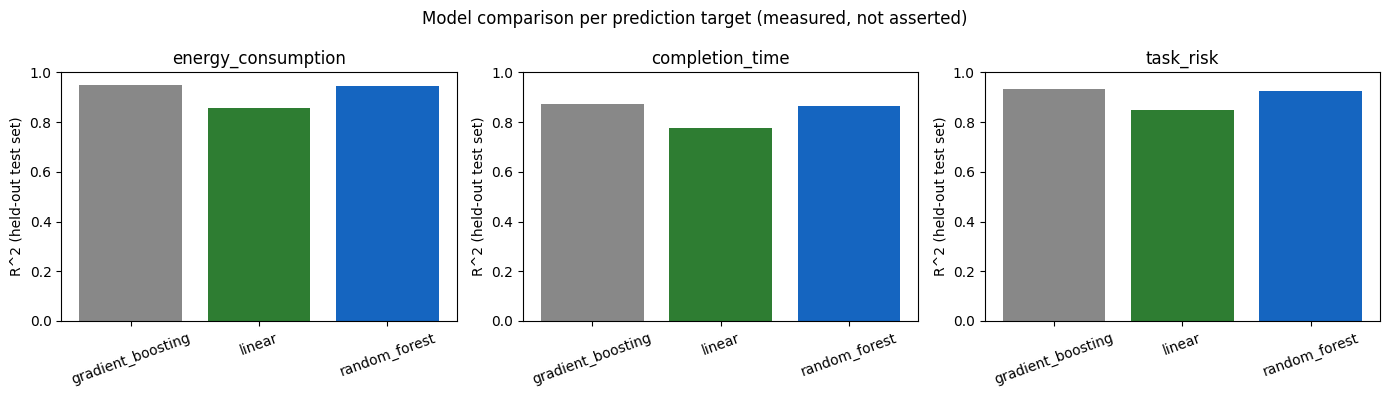

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, target in zip(axes, TARGETS):
    sub = results_df[results_df.target == target].sort_values("model")
    ax.bar(sub["model"], sub["R2"], color=["#888", "#2e7d32", "#1565c0"])
    ax.set_title(target)
    ax.set_ylabel("R^2 (held-out test set)")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Model comparison per prediction target (measured, not asserted)")
fig.tight_layout()
fig.savefig("../results/day4_ml_model_comparison.png", dpi=150, bbox_inches="tight")


### Prediction diagnostics for the best model per target

A single R² number can hide systematic bias. These predicted-vs-actual
scatter plots (with the y=x reference line) and residual distributions
give a fuller, more honest picture of where each model over/under-predicts.

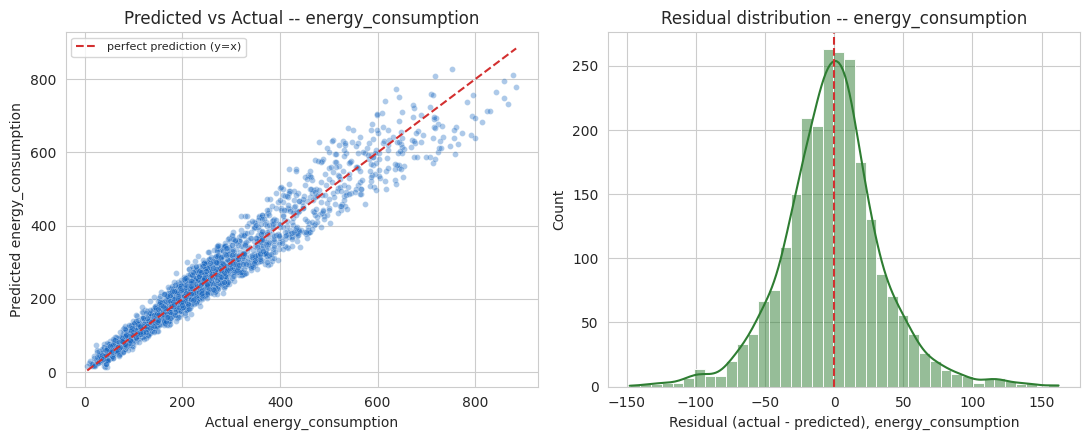

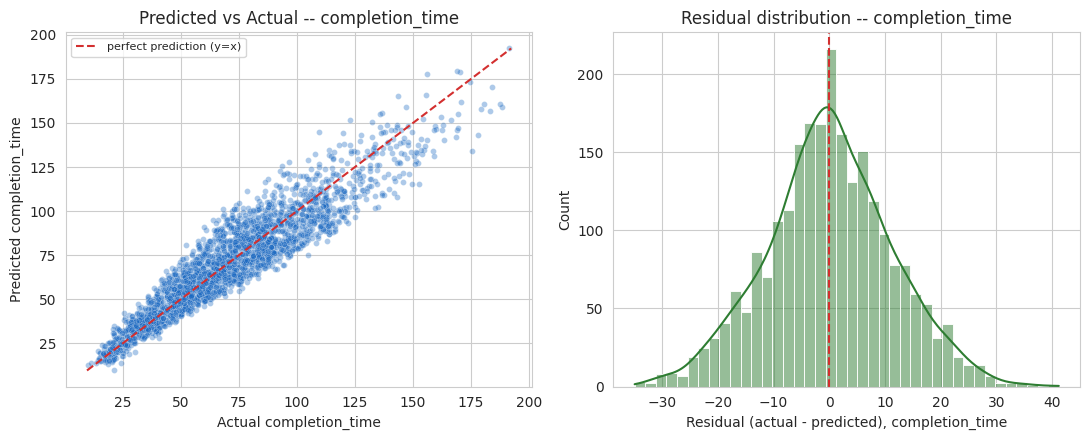

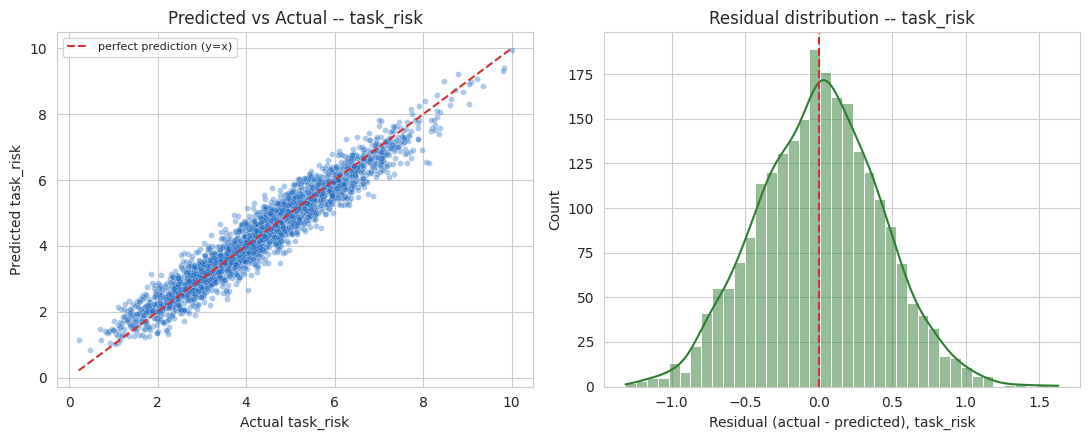

In [5]:
from sklearn.model_selection import train_test_split
from visualization import plot_prediction_diagnostics

for target in TARGETS:
    X = df[FEATURES_ALL]
    y = df[target]
    _, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    best_path = [row["path"] for row in __import__("json").load(open(os.path.join(MODELS_DIR, "ml_prediction_metrics.json")))
                 if row.get("target") == target and "selected_best_model" in row][0]
    import joblib as _joblib
    best_model = _joblib.load(best_path)
    y_pred = best_model.predict(X_test)
    plot_prediction_diagnostics(y_test.values, y_pred, target,
                                 savepath=f"../results/day4_pred_diagnostics_{target}.png")
    plt.show()


## Feature importance (Random Forest, energy_consumption)

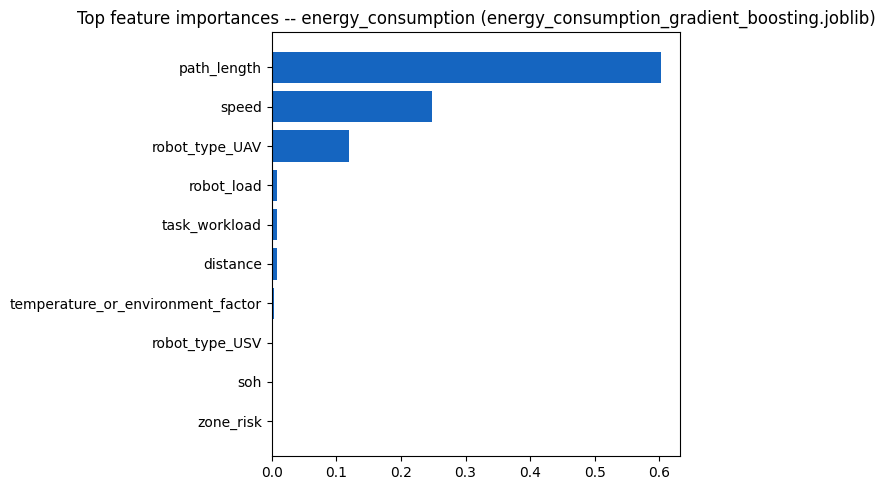

In [6]:
import joblib
import numpy as np

rf_energy_path = os.path.join(MODELS_DIR, "energy_consumption_gradient_boosting.joblib")
if not os.path.exists(rf_energy_path):
    rf_energy_path = os.path.join(MODELS_DIR, "energy_consumption_random_forest.joblib")

pipe = joblib.load(rf_energy_path)
model = pipe.named_steps["model"]
pre = pipe.named_steps["pre"]
cat_names = list(pre.named_transformers_["cat"].get_feature_names_out(["robot_type", "zone_type"]))
numeric_names = [c for c in FEATURES_ALL if c not in ("robot_type", "zone_type")]
feature_names = cat_names + numeric_names

if hasattr(model, "feature_importances_"):
    importances = model.feature_importances_
    order = np.argsort(importances)[::-1][:10]
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh([feature_names[i] for i in order][::-1], importances[order][::-1], color="#1565c0")
    ax.set_title(f"Top feature importances -- energy_consumption ({os.path.basename(rf_energy_path)})")
    fig.tight_layout()
    fig.savefig("../results/day4_feature_importance_energy.png", dpi=150, bbox_inches="tight")
else:
    print("Selected model has no feature_importances_ attribute (e.g. Linear).")


## Load the saved Predictor and make a sample prediction

In [7]:
predictor = Predictor(models_dir=MODELS_DIR)
sample = {
    "soc": 79.3, "dod": 20.7, "soh": 0.916, "distance": 20.0, "path_length": 24.0,
    "speed": 3.5, "task_workload": 8.0, "task_priority": 4, "zone_risk": 2.0,
    "robot_load": 0.5, "temperature_or_environment_factor": 25.0,
    "robot_type": "UGV", "zone_type": "LAND",
}
pred = predictor.predict(sample)
print("Predicted:", pred)
assert set(pred.keys()) == {"predicted_energy", "predicted_time", "predicted_risk"}


Predicted: {'predicted_energy': 75.48831263090158, 'predicted_time': 23.70769953456747, 'predicted_risk': 3.677002066540283}


## Wire predictions into the auction (Section 19: feeds the auction)

In [8]:
from environment import Environment
from robots import RobotFleet
from tasks import TaskManager
from battery import BatteryModel
from auction import run_auction, compute_bid

env = Environment(DATASET_ROOT)
fleet = RobotFleet(DATASET_ROOT)
batt = BatteryModel(fleet, DATASET_ROOT)
tm = TaskManager(DATASET_ROOT)

# Compare one bid with vs without ML augmentation, side by side
robot = fleet.robots["UGV01"]
task = tm.tasks["T02"]
bid_physics_only = compute_bid(robot, task, env, batt)
bid_with_ml = compute_bid(robot, task, env, batt, predictor=predictor)

print("Physics-only bid:\n ", bid_physics_only.explanation())
print("\nML-augmented bid:\n ", bid_with_ml.explanation())


Physics-only bid:
  UGV01 -> T02 | score=0.594 | priority=0.600, distance_cost=0.396, path_cost=0.442, predicted_energy=0.467, soc=0.793, dod=0.793, soh=0.916, risk=0.250, deadline=1.000, workload_fairness=1.000, predicted_energy_wh=213.282, distance_raw=72.426

ML-augmented bid:
  UGV01 -> T02 | score=0.598 | priority=0.600, distance_cost=0.396, path_cost=0.442, predicted_energy=0.471, soc=0.793, dod=0.793, soh=0.916, risk=0.290, ml_predicted_energy_wh=262.688, ml_predicted_time=130.668, ml_predicted_risk=6.698, deadline=1.000, workload_fairness=1.000, predicted_energy_wh=213.282, distance_raw=72.426


In [9]:
assignment = run_auction(list(fleet.robots.values()), tm.active_tasks(), env, batt, predictor=predictor)
print(f"ML-augmented auction assigned {len(assignment)} / {len(fleet.robots)} robots")
emergency_ids = {t.task_id for t in tm.active_tasks() if t.emergency}
won_emergency = [b for b in assignment.values() if b.task_id in emergency_ids]
print(f"Emergency tasks won: {len(won_emergency)} / {len(emergency_ids)}")
assert len(assignment) > 0


ML-augmented auction assigned 12 / 12 robots
Emergency tasks won: 3 / 3
